<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/7%EC%A3%BC%EC%B0%A8/10_26_mobile_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. 라이브러리 & 데이터 불러오기

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile.csv")

=== 결측치 ===
0 개

중복 행: 0 개

=== 이상치 개수 (IQR) ===
battery_power: 0개
clock_speed: 0개
fc: 18개
int_memory: 0개
m_dep: 0개
mobile_wt: 0개
n_cores: 0개
pc: 0개
px_height: 2개
px_width: 0개
ram: 0개
sc_h: 0개
sc_w: 0개
talk_time: 0개


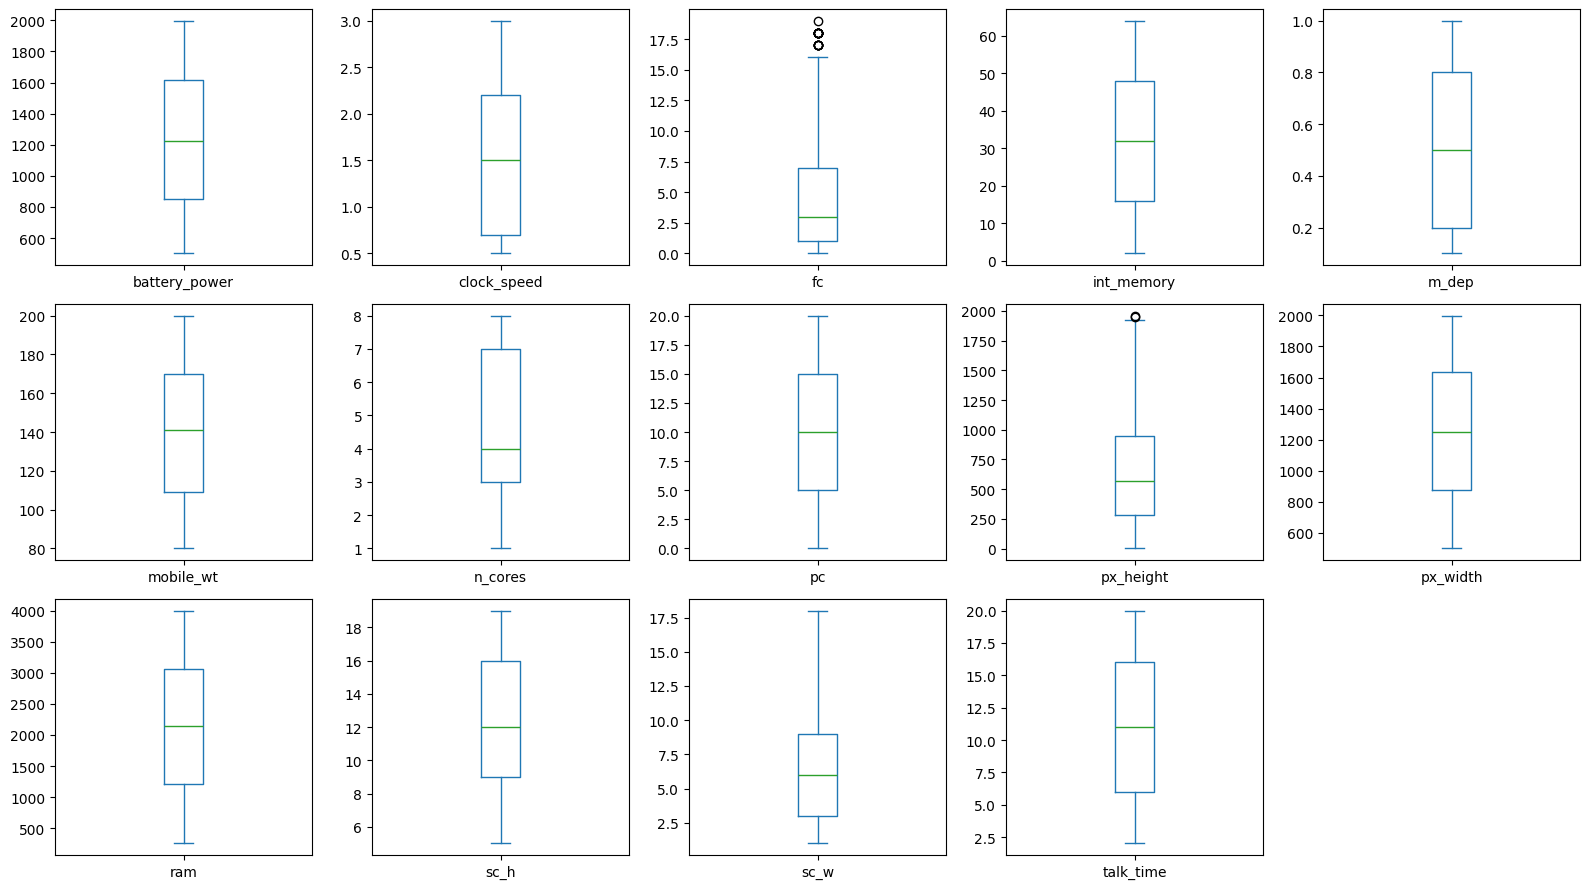


=== 노이즈 확인 ===
px_height == 0: 0 개
sc_w == 0     : 0 개

=== battery_power와의 상관관계 ===
battery_power    1.000000
talk_time        0.051655
m_dep            0.035201
fc               0.032821
pc               0.031344
four_g           0.015404
px_height        0.015347
blue             0.012329
three_g          0.011369
clock_speed      0.011238
mobile_wt        0.002788
ram             -0.001694
int_memory      -0.004951
wifi            -0.008059
px_width        -0.009801
touch_screen    -0.010815
sc_w            -0.021527
n_cores         -0.029017
sc_h            -0.030591
dual_sim        -0.041599
Name: battery_power, dtype: float64


In [7]:
# 2. EDA
## 결측치
print("=== 결측치 ===")
print(df.isnull().sum().sum(), "개")

## 중복
print("\n중복 행:", df.duplicated().sum(), "개")

## 이상치 (IQR 기준, 0/1 값 컬럼은 제외)
print("\n=== 이상치 개수 (IQR) ===")
num_cols = [c for c in df.columns if df[c].nunique() > 2 and c != "price_range"]
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n}개")

## 박스플롯
df[num_cols].plot(kind="box", subplots=True, layout=(3, 5), figsize=(16, 9))
plt.tight_layout(); plt.show()

## 말이 안 되는 값 (노이즈)
print("\n=== 노이즈 확인 ===")
print("px_height == 0:", (df["px_height"] == 0).sum(), "개")
print("sc_w == 0     :", (df["sc_w"] == 0).sum(), "개")

## battery_power와의 상관관계
print("\n=== battery_power와의 상관관계 ===")
print(df.drop(columns=["price_range"]).corr()["battery_power"].sort_values(ascending=False))

In [8]:
# 3. 전처리
## 결측치 / 중복 : 없음
## IQR 이상치 : 박스플롯에서 이어진 꼬리 형태라 실제 값으로 판단 → 유지
## 노이즈 제거 :
### px_height (화면 세로 픽셀) == 0 인 값은 물리적으로 불가능 → 제거 (2개)
### sc_w (화면 너비) == 0 인 값도 노이즈지만 전체의 9%라 제거하기엔 많고,
### battery_power와 상관이 낮은 특성이므로 중앙값으로 대체

df = df[df["px_height"] > 0].reset_index(drop=True)

sc_w_median = df.loc[df["sc_w"] > 0, "sc_w"].median()
df.loc[df["sc_w"] == 0, "sc_w"] = sc_w_median

In [9]:
# 4. 입력 / 정답 나누기 (price_range 제거)
X = df.drop(columns=["battery_power", "price_range"]).values.astype("float32")
y = df["battery_power"].values.astype("float32")
print("X 모양:", X.shape, "| y 모양:", y.shape)

X 모양: (1998, 19) | y 모양: (1998,)


In [10]:
# 5. 학습 / 테스트 분할 + 스케일링
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# 6. 모델 구성: 회귀 → 출력 노드 1개, 활성화 함수 없음
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1),
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 7. 학습
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                         min_delta=1.0, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=300, batch_size=32,
                    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1694108.5000 - mae: 1225.5262 - val_loss: 1811400.7500 - val_mae: 1266.6161
Epoch 2/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1683164.7500 - mae: 1221.0541 - val_loss: 1795529.3750 - val_mae: 1260.3473
Epoch 3/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1660063.5000 - mae: 1211.6696 - val_loss: 1762519.2500 - val_mae: 1247.1984
Epoch 4/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1614891.8750 - mae: 1192.8480 - val_loss: 1701702.6250 - val_mae: 1222.5706
Epoch 5/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1537730.3750 - mae: 1159.8644 - val_loss: 1605609.0000 - val_mae: 1182.5153
Epoch 6/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1422012.1250 - mae: 1109.0646 - val_loss: 1469590.1250 - val_mae: 1123.1849
Epoch 7/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1266755.7500 - mae: 1036.3500 - val_loss: 1297396.0000 - val_mae: 1042.8055
Epoch 8/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - lo

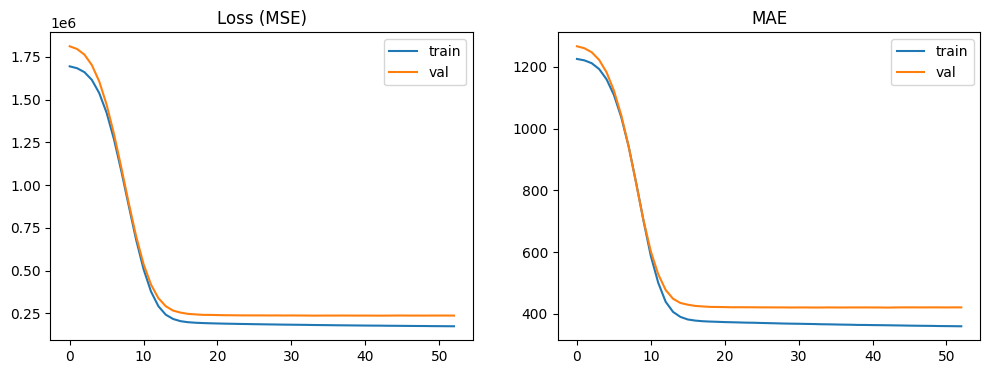

In [13]:
# 8. 학습 곡선
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss (MSE)"); axes[0].legend()
axes[1].plot(history.history["mae"], label="train")
axes[1].plot(history.history["val_mae"], label="val")
axes[1].set_title("MAE"); axes[1].legend()
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
MAE : 379.612060546875
RMSE: 446.4641117995936
R²  : -0.09116792678833008
기준선 MAE: 366.95269775390625


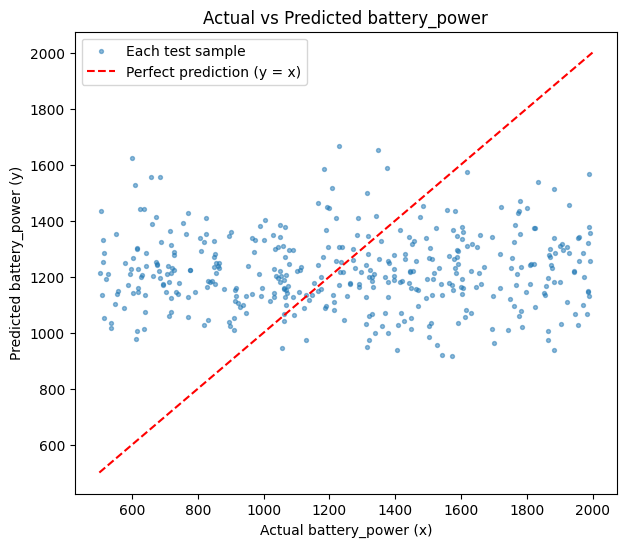

In [15]:
# 9. 평가
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test).flatten()

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))

# 기준선: 모든 값을 train 평균으로 예측했을 때
baseline = np.full_like(y_test, y_train.mean())
print("기준선 MAE:", mean_absolute_error(y_test, baseline))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, s=8, alpha=0.5, label="Each test sample")
plt.plot([500, 2000], [500, 2000], "r--", label="Perfect prediction (y = x)")

plt.xlabel("Actual battery_power (x)")
plt.ylabel("Predicted battery_power (y)")
plt.title("Actual vs Predicted battery_power")
plt.legend()
plt.show()

In [ ]:
# 11. 결과 분석
1. 일단 위에 EDA 단계에서 상관계수 구해보니까 battery_power 와 다른 나머지 특성들 간의 상관관계가 0에 가까워서
battery_power를 예측하기에는 해당 특성들이 도움이 안된다는 것을 알 수 있다

2. 위에 산점도를 분석해보면 점들이 가로로 납작한 띠 모양임을 알 수 있다. 즉 , 실제값이 600이든, 2000이든 예측을
대부분 1000~1400 사이 가운데 1200 근처에 몰려있는 것을 알 수 있다.
